# Pathway enrichment of chemical signatures in MCF7 (LINCS L1000)

For each compound class, genes consistently deregulated across the L1000
signatures are selected with a gene-level score (section 2), then tested for
KEGG and GO Biological Process over-representation.

**Produces** Figures 1 and 2 of the article, and Supplementary Tables S1-S10
(`../../results/tables/ora_l1000/`).

**Naming**: the article calls the two classes **MC** (mammary carcinogens) and
**SMC** (suspected mammary carcinogens). The SMC list is drawn from
endocrine-disruptor databases, so the input file is named `ED_merge.csv`;
`SMC` and `ED` denote the same compound set throughout this repository.

Each class is analysed twice: on the 978 **landmark** genes measured directly
(`L`), and on landmark **+ best-inferred** genes (`LBI`), whose inferred part
carries its own error — which is why the two are reported separately.

In [1]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "..")
from common import dose_window, enrich, g_scores, gene_ids_to_symbols

TABLES = "../../results/tables/ora_l1000"
FIGURES = "../../figures"

Z_CUTOFF = 2          # z-score threshold for calling a gene up- or down-regulated
TIME = "24 h"         # exposure time kept
DOSE_MIN, DOSE_MAX = 0.1, 1.3   # micromolar window ("concentration 1")
TOP_N = 25            # pathways shown per panel
GENE_SETS = {"kegg": "KEGG_2021_Human", "go": "GO_Biological_Process_2021"}

## 1. Data

In [2]:
gene_info = pd.read_csv("../../data/lincs-metadata/geneinfo_beta.txt", sep="\t")
landmark_genes = [
    str(g) for g in gene_info.loc[gene_info["feature_space"] == "landmark", "gene_id"]
]

# MCF7 signatures, one per compound-dose-time condition (best TAS replicate),
# regenerated by analyses/02_lincs_extraction/extract_L1000_l_bi.py
profiles_lbi = pd.read_csv("../../data/external/L1000/L1000_MCF7_l_bi_bestTAS.csv")
profiles_l = pd.concat(
    [profiles_lbi.iloc[:, :7], profiles_lbi.loc[:, landmark_genes]], axis=1
)
print(f"{profiles_lbi.shape[0]} signatures, "
      f"{profiles_lbi.shape[1] - 7} genes (landmark + best inferred), "
      f"{len(landmark_genes)} landmark genes")

47654 signatures, 10174 genes (landmark + best inferred), 978 landmark genes


In [3]:
mc_meta = (
    pd.read_csv("../../data/lincs-metadata/MC_merge.csv")
    .rename(columns={"inchi_key": "inchikey"})
    .drop_duplicates(subset=["inchikey"])
)

# The SMC list is cleaned of compounds already classified as MC, so that the two
# classes are disjoint and the enrichments are not driven by shared compounds.
smc_meta = pd.read_csv("../../data/lincs-metadata/ED_merge.csv").rename(
    columns={"inchi_key": "inchikey"}
)
smc_meta = smc_meta[~smc_meta["inchikey"].isin(mc_meta["inchikey"])].drop_duplicates(
    subset=["inchikey"]
)
print(f"MC: {len(mc_meta)} compounds | SMC: {len(smc_meta)} compounds (MC removed)")

MC: 53 compounds | SMC: 173 compounds (MC removed)


## 2. Gene-level score

A gene is retained when its deregulation is both strong and consistent across
the signatures of the class. For each gene, signatures are split into those
passing the z-score threshold ($s$) and those not ($ns$):

$G_{score} = | \overline{s} \cdot [1 + \frac{s}{s+ns}]| - |\overline{ns} \cdot [1 + \frac{ns}{s+ns}]|$

$score_{cutoff} = |\overline{s}_N \cdot 1.5| - |\overline{ns}_N \cdot 1.5|$

where $\overline{s}$ and $\overline{ns}$ are the mean values of the passing and
non-passing signatures for that gene, and $\overline{s}_N$, $\overline{ns}_N$
the same means taken over all genes. Genes above $score_{cutoff}$ are kept.

Implemented in `../common.py`, shared with
`analyses/06_wgcna_networks/02_compound_gene_networks.ipynb`.

## 3. Enrichment, per class and per feature space

Four analyses per class (landmark / landmark+best-inferred x up / down), each
giving a KEGG and a GO table — the ten tables reported as S1-S10.

In [4]:
subsets = {
    ("MC", "L"): profiles_l[profiles_l["inchikey"].isin(mc_meta["inchikey"])],
    ("MC", "LBI"): profiles_lbi[profiles_lbi["inchikey"].isin(mc_meta["inchikey"])],
    ("SMC", "L"): profiles_l[profiles_l["inchikey"].isin(smc_meta["inchikey"])],
    ("SMC", "LBI"): profiles_lbi[profiles_lbi["inchikey"].isin(smc_meta["inchikey"])],
}

results = {}
for (chem_class, space), profiles in subsets.items():
    profiles = profiles[profiles["time"] == TIME]
    doses = dose_window(profiles["dose"].unique(), DOSE_MIN, DOSE_MAX)
    data = profiles[profiles["dose"].isin(doses)].iloc[:, 7:]
    print(f"{chem_class:3s} {space:3s}: {data.shape[0]:4d} signatures, "
          f"{profiles['inchikey'].nunique()} compounds, {len(doses)} doses")

    for direction in ("up", "down"):
        symbols = gene_ids_to_symbols(gene_info, g_scores(data, z_cutoff=Z_CUTOFF, direction=direction))
        for library, gene_set in GENE_SETS.items():
            results[(chem_class, space, direction, library)] = enrich(symbols, gene_set)
        print(f"      {direction:4s}: {len(symbols)} genes selected")

MC  L  :   89 signatures, 34 compounds, 7 doses


      up  : 107 genes selected


      down: 60 genes selected
MC  LBI:   89 signatures, 34 compounds, 7 doses


      up  : 449 genes selected


      down: 204 genes selected
SMC L  :  334 signatures, 127 compounds, 11 doses


      up  : 73 genes selected


      down: 33 genes selected
SMC LBI:  334 signatures, 127 compounds, 11 doses


      up  : 341 genes selected


      down: 167 genes selected


In [5]:
# Supplementary Tables S1-S10: significant pathways only.
for (chem_class, space, direction, library), res in results.items():
    table = res.res2d
    table = table[table["Adjusted P-value"] < 0.05]
    table.to_csv(f"{TABLES}/{chem_class}/{space}_enrich_{library}_{direction}.csv")
print(f"{len(results)} tables written to {TABLES}/")

16 tables written to ../../results/tables/ora_l1000/


## 4. Figures 1 and 2

Four panels per class: KEGG pathways up-regulated on landmark genes (A) and on
landmark + best-inferred genes (B), then the same two for down-regulated genes
(C, D). Comparing the two feature spaces is the point of the figure: it shows
which enrichments survive when only directly measured genes are used.

The published PDFs were assembled from two separate two-panel figures; the
2x2 layout below reproduces them in one step, so the output is equivalent in
content but not byte-identical to the files in `../../figures/`.

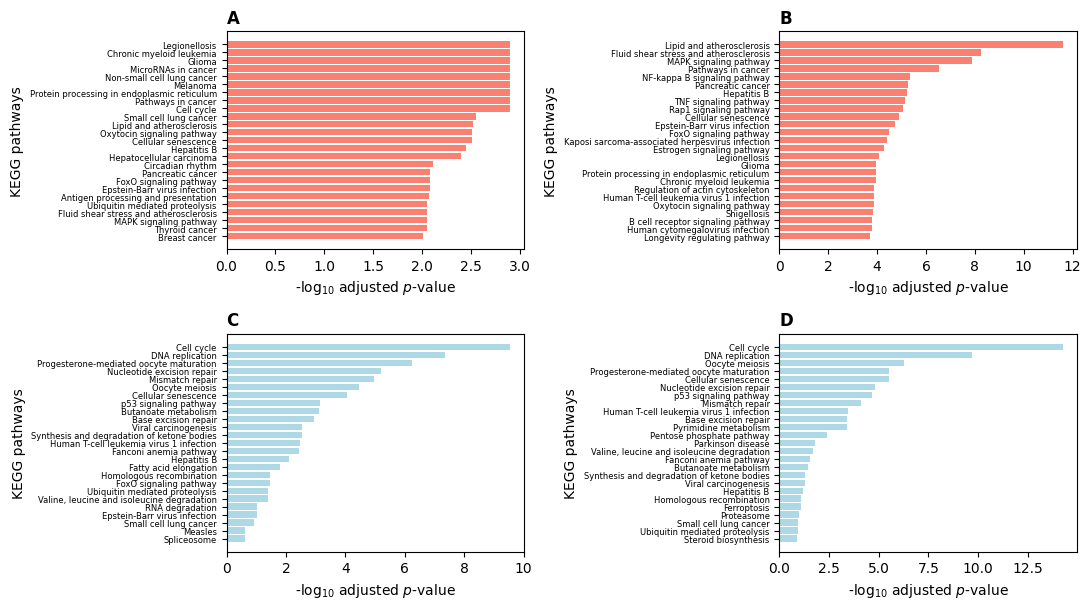

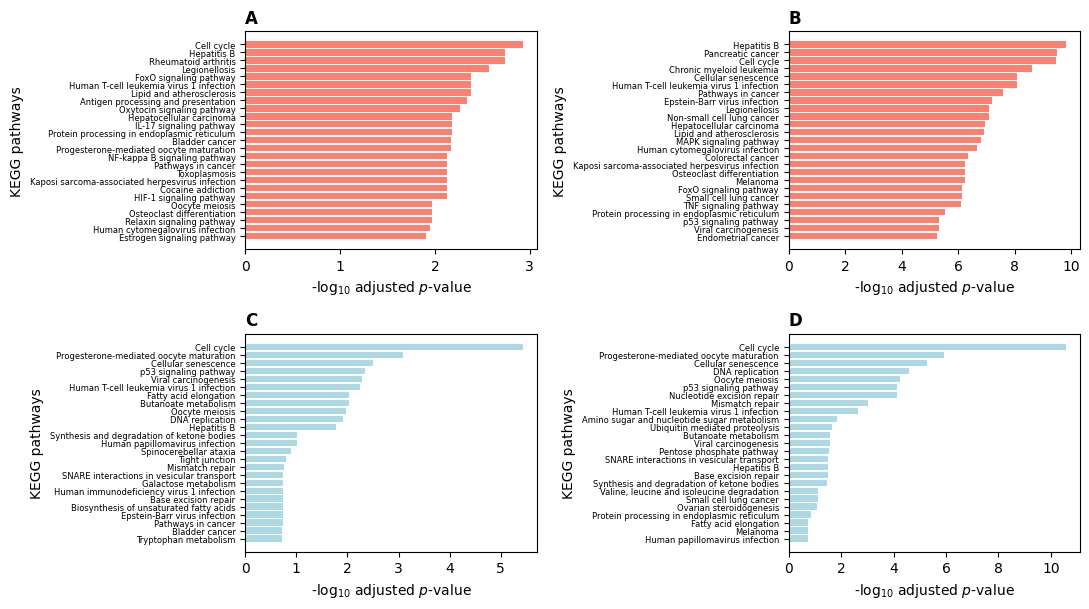

In [6]:
def panel(ax, res, color, label):
    """One horizontal barplot of the top pathways, by adjusted p-value."""
    table = res.res2d.assign(
        logAP=-np.log10(res.res2d["Adjusted P-value"].values)
    )[["Term", "logAP"]].head(TOP_N)
    table = table[table["logAP"] > 0.05].sort_values("logAP")

    ax.barh([t.split("(")[0] for t in table["Term"]], table["logAP"], color=color)
    ax.set_xlabel("-log$_{10}$ adjusted $p$-value")
    ax.set_ylabel("KEGG pathways")
    ax.tick_params(axis="y", labelsize=6)
    ax.set_title(label, loc="left", fontweight="bold")


def class_figure(chem_class, filename):
    fig, axes = plt.subplots(2, 2, figsize=(11, 6.2))
    panels = [
        ("L", "up", "salmon", "A"),
        ("LBI", "up", "salmon", "B"),
        ("L", "down", "lightblue", "C"),
        ("LBI", "down", "lightblue", "D"),
    ]
    for ax, (space, direction, color, label) in zip(axes.ravel(), panels):
        panel(ax, results[(chem_class, space, direction, "kegg")], color, label)
    plt.tight_layout()
    for ext in ("png", "pdf"):
        fig.savefig(f"{FIGURES}/{filename}.{ext}", dpi=500, bbox_inches="tight")
    plt.show()


class_figure("MC", "Figure-1_ORA_Deregulated_MC_L1000")
class_figure("SMC", "Figure-2_ORA_Deregulated_SMC_L1000")